In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
from utils_spec import *
import os
from tqdm import tqdm
import json
from datetime import date

In [2]:
# Get the current date
todays_date = date.today()
year = str(todays_date.year)
if todays_date.month < 10:
    month = '0'+str(todays_date.month)
else:
    month = str(todays_date.month)

if todays_date.day < 10:
    day = '0'+str(todays_date.day)
else:
    day = str(todays_date.day)

current_date = year+month+day
directory_name = 'results/'+current_date
if not os.path.isdir(directory_name):
    os.mkdir(directory_name)
    
directory_name

'results/20260507'

In [3]:
#directory_name = 'results/20251026'
#directory_name

In [3]:
remove_slopp = pd.read_excel('RochmanSpectra_ToRemove.xlsx', sheet_name="SLOPPe Remove")

mIRageLibraySpectra_Removed = pd.read_csv('../gloves_contamination/mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'

dict_slopp_reb = {'PE':'Polyethylene', 
                  'PP':'Polypropylene', 
                  'PSL':'Polystyrene'}

with open('processed_data/passive_data_raman_saturation.json', 'r') as f:
    saturated_wn_dict = json.load(f)

    
ids_sat = list(saturated_wn_dict.keys())

slopp_df = pd.read_csv('processed_data/slopp_data_raman_final_specy.csv')
del slopp_df['Unnamed: 0']
slopp_df.columns = list(np.float64(slopp_df.columns[:-4])) + list(slopp_df.columns[-4:])

slopp_df = slopp_df.query('polymer != "Cotton" and polymer !="Dyed Cellulose"').reset_index(drop=True)
slopp_df.loc[slopp_df['polymer'] == "Polyester",'polymer'] = "Polyethylene Terephthalate"
slopp_df = slopp_df.loc[[x not in np.array(remove_slopp['Example']) for x in slopp_df['id']], :].reset_index(drop=True)

rebecca_raman_df = pd.read_csv('processed_data/rebecca_data_raman_final_specy.csv')
del rebecca_raman_df['Unnamed: 0']
rebecca_raman_df.columns = list(np.float64(rebecca_raman_df.columns[:-4])) + list(rebecca_raman_df.columns[-4:])

rebecca_raman_df = rebecca_raman_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "Raman"')['ID']) for x in rebecca_raman_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_raman_df = rebecca_raman_df.query('polymer in @dict_slopp_reb').reset_index(drop=True)
rebecca_raman_df['polymer'] = [dict_slopp_reb[x] for x in rebecca_raman_df['polymer']]

passive_data_raman = pd.read_csv('processed_data/passive_data_raman_specy.csv')
del passive_data_raman['Unnamed: 0']
del passive_data_raman['wn_saturated']
del passive_data_raman['id_file']
ids_no_signal = np.array(passive_data_raman.query('no_signal>0')['id'])
del passive_data_raman['no_signal']
passive_data_raman.columns = list(np.float64(passive_data_raman.columns[:-3])) + list(passive_data_raman.columns[-3:])
passive_data_raman['polymer'] = ''
passive_data_raman['label'] = ''


#1850-2750

wn_raman = np.float64(slopp_df.columns[:-4])

min_raman_1 = 600
max_raman_1 = 1000

min_raman_2 = 1600
max_raman_2 = 3500

idx_1 = list(np.logical_or(
    np.logical_and(
        wn_raman > min_raman_1,
        wn_raman < max_raman_1),
    np.logical_and(
        wn_raman > min_raman_2,
        wn_raman < max_raman_2))) + [True]*4

min_raman_1 = 600
max_raman_1 = 910

min_raman_2 = 1040
max_raman_2 = 2310

min_raman_3 = 2500
max_raman_3 = 3500

#min_raman_1 = 600
#max_raman_1 = 1000

#min_raman_2 = 1600
#max_raman_2 = 3500

#min_raman_3 = 2500
#max_raman_3 = 3500

idx_1 = list(
    np.logical_or( 
        np.logical_or(
            np.logical_and(
                wn_raman > min_raman_1,
                wn_raman < max_raman_1),
            np.logical_and(
                wn_raman > min_raman_2,
                wn_raman < max_raman_2)
            ),   
        np.logical_and(
            wn_raman > min_raman_3,
            wn_raman < max_raman_3)
    )
    ) + [True]*4

idx_2 = idx_1[:-4] + [False]*4

slopp_df = slopp_df.loc[:,idx_1]
rebecca_raman_df = rebecca_raman_df.loc[:,idx_1]
passive_data_raman = passive_data_raman.loc[:,idx_1+[True]]
#passive_data_raman = passive_data_raman.query('id != "DC_passive_June2024_I7_20240717_90"').reset_index(drop=True)

slopp_df.iloc[:,:-4] = (slopp_df.iloc[:,:-4] - slopp_df.iloc[:,:-4].mean(1).to_numpy()[:,None]) / slopp_df.iloc[:,:-4].std(1).to_numpy()[:,None]
rebecca_raman_df.iloc[:,:-4] = (rebecca_raman_df.iloc[:,:-4] - rebecca_raman_df.iloc[:,:-4].mean(1).to_numpy()[:,None]) / rebecca_raman_df.iloc[:,:-4].std(1).to_numpy()[:,None]
passive_data_raman.iloc[:,:-5] = (passive_data_raman.iloc[:,:-5] - passive_data_raman.iloc[:,:-5].mean(1).to_numpy()[:,None]) / passive_data_raman.iloc[:,:-5].std(1).to_numpy()[:,None]

ids_no_signal = np.unique(
    np.concatenate([ids_no_signal,
    np.array(passive_data_raman.loc[passive_data_raman.iloc[:,:-5].T.std()<.01,'id'])]))

idx_raman_nan = np.unique(np.where(np.isnan(passive_data_raman.iloc[:,:-5]))[0])


In [110]:
slopp_df.to_csv(directory_name+'/slopp_data_raman_final_specy.csv')

In [4]:
2

2

In [103]:
passive_data_raman.to_csv(directory_name+'/passive_data_raman_specy.csv')

In [108]:
label_table_ir.to_csv(directory_name+'/label_table_ir.csv')

In [4]:
#passive_data_raman['saturation'] = [x in ids_sat for x in passive_data_raman['id']]
#passive_data_raman['no_signal'] = [x in ids_no_signal for x in passive_data_raman['id']]
#passive_data_raman.to_csv(directory_name+'/passive_data_raman_specy.csv')

In [5]:
#slopp_df.to_csv(directory_name+'/slopp_data_raman_final_specy.csv')

In [6]:
min(slopp_df.iloc[:,:-5].mean(1)),max(slopp_df.iloc[:,:-5].mean(1))

(-0.00030515265476993466, 0.0005147944435378851)

In [5]:
min(slopp_df.iloc[:,:-5].mean(1)),max(slopp_df.iloc[:,:-5].mean(1))

(-0.00030515265476993466, 0.0005147944435378851)

In [6]:
min(slopp_df.iloc[:,:-5].std(1)),max(slopp_df.iloc[:,:-5].std(1))

(1.00021841242261, 1.000389011196785)

In [5]:
remove_flopp = pd.read_excel('RochmanSpectra_ToRemove.xlsx', sheet_name="FLOPPe Remove")

flopp_df = pd.read_csv('processed_data/flopp_data_ir_final.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.loc[[x not in np.array(remove_flopp['Example']) for x in flopp_df['id']], :].reset_index(drop=True)

rebecca_ir_df = pd.read_csv('processed_data/rebecca_data_ir_final.csv')
del rebecca_ir_df['Unnamed: 0']
rebecca_ir_df.columns = list(np.float64(rebecca_ir_df.columns[:-4])) + list(rebecca_ir_df.columns[-4:])

rebecca_ir_df = rebecca_ir_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "PTIR"')['ID']) for x in rebecca_ir_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_ir_df = rebecca_ir_df.query('polymer in @dict_slopp_reb').reset_index(drop=True)
rebecca_ir_df['polymer'] = [dict_slopp_reb[x] for x in rebecca_ir_df['polymer']]


passive_data_ir = pd.read_csv('processed_data/passive_data_ir.csv')
del passive_data_ir['Unnamed: 0']
background_ids = np.array(passive_data_ir.query('background == "background"')['id'])
passive_data_ir.columns = list(np.float64(passive_data_ir.columns[:-4])) + list(passive_data_ir.columns[-4:])
passive_data_ir['polymer'] = ''
passive_data_ir['label'] = ''

#passive_data_ir = passive_data_ir.query('id != "DC_passive_June2024_I7_20240717_90"').reset_index(drop=True)

flopp_df.iloc[:,:-4] = (flopp_df.iloc[:,:-4] - flopp_df.iloc[:,:-4].mean(1).to_numpy()[:,None]) / flopp_df.iloc[:,:-4].std(1).to_numpy()[:,None]
rebecca_ir_df.iloc[:,:-4] = (rebecca_ir_df.iloc[:,:-4] - rebecca_ir_df.iloc[:,:-4].mean(1).to_numpy()[:,None]) / rebecca_ir_df.iloc[:,:-4].std(1).to_numpy()[:,None]
passive_data_ir.iloc[:,:-6] = (passive_data_ir.iloc[:,:-6] - passive_data_ir.iloc[:,:-6].mean(1).to_numpy()[:,None]) / passive_data_ir.iloc[:,:-6].std(1).to_numpy()[:,None]

In [105]:
passive_data_ir.to_csv(directory_name+'/passive_data_ir.csv')

In [9]:
#particle_info = pd.read_csv('processed_data/passive_data_raman_specy_particle_info.csv')
#particle_info = particle_info.loc[:,['id','size','area','perimeter','circularity','distance']]
#particle_info.to_csv('processed_data/particle_info_passive_data.csv')

In [8]:
passive_data_ir = passive_data_ir.loc[["ICB" not in x for x in passive_data_ir['id']],:].reset_index(drop=True)
passive_data_raman = passive_data_raman.loc[["ICB" not in x for x in passive_data_raman['id']],:].reset_index(drop=True)


In [9]:
particle_info_passive_data = pd.read_csv('particle_info_passive_data.csv')
del particle_info_passive_data['Unnamed: 0']

In [10]:
passive_data_ir = passive_data_ir.merge(particle_info_passive_data, on='id', how='left').iloc[:,-11:].drop(['polymer', 'label', 'background'], axis=1)


In [11]:
removed_files = [
    'MEC_02_119_DC_Sp_S6_SquareAlSi_20240502', 
    'MEC_04_014_DC_Active_20240808_S4_GridSi_20241008',  
    'MEC_04_014_DC_Active_20240808_S6_ThinSi_20241008']


In [12]:
passive_data_ir

,map_x,map_y,id,size,area,perimeter,circularity,distance
0,15435.200195,1589.199951,FHS_passive_August2024_B4_20240910_1,2.481553,5.130047,9.054808,0.786066,0.400617
1,15436.750000,1599.699951,FHS_passive_August2024_B4_20240910_2,0.849944,0.584114,3.109362,0.759017,0.269211
2,15392.150391,1603.900024,FHS_passive_August2024_B4_20240910_3,0.623239,0.304755,2.297185,0.725531,0.335258
3,15437.599609,1606.650024,FHS_passive_August2024_B4_20240910_4,0.638054,0.296290,2.220973,0.754617,0.218255
4,15439.450195,1611.050049,FHS_passive_August2024_B4_20240910_5,0.997186,0.736492,3.477345,0.765189,0.296224
...,...,...,...,...,...,...,...,...
6144,7783.100098,-485.600006,IAO_passive_June2024_G7_20240801_39,0.770292,0.448667,2.588956,0.840953,0.346708
6145,7778.299805,-487.200012,IAO_passive_June2024_G7_20240801_40,6.770013,35.935730,23.300610,0.831550,0.247018
6146,7740.350098,-478.950012,IAO_passive_June2024_G7_20240801_41,1.230288,1.041247,5.101700,0.502598,0.447553
6147,7828.049805,-470.100006,IAO_passive_June2024_G7_20240801_42,0.671796,0.364013,2.804515,0.581431,0.324645


In [13]:
np.where([any([y in x for y in removed_files]) for x in passive_data_ir['id']])

(array([], dtype=int64),)

In [14]:
passive_data_ir['school'] = [x.split("_")[0] for x in passive_data_ir['id']]
passive_data_ir

,map_x,map_y,id,size,area,perimeter,circularity,distance,school
0,15435.200195,1589.199951,FHS_passive_August2024_B4_20240910_1,2.481553,5.130047,9.054808,0.786066,0.400617,FHS
1,15436.750000,1599.699951,FHS_passive_August2024_B4_20240910_2,0.849944,0.584114,3.109362,0.759017,0.269211,FHS
2,15392.150391,1603.900024,FHS_passive_August2024_B4_20240910_3,0.623239,0.304755,2.297185,0.725531,0.335258,FHS
3,15437.599609,1606.650024,FHS_passive_August2024_B4_20240910_4,0.638054,0.296290,2.220973,0.754617,0.218255,FHS
4,15439.450195,1611.050049,FHS_passive_August2024_B4_20240910_5,0.997186,0.736492,3.477345,0.765189,0.296224,FHS
...,...,...,...,...,...,...,...,...,...
6144,7783.100098,-485.600006,IAO_passive_June2024_G7_20240801_39,0.770292,0.448667,2.588956,0.840953,0.346708,IAO
6145,7778.299805,-487.200012,IAO_passive_June2024_G7_20240801_40,6.770013,35.935730,23.300610,0.831550,0.247018,IAO
6146,7740.350098,-478.950012,IAO_passive_June2024_G7_20240801_41,1.230288,1.041247,5.101700,0.502598,0.447553,IAO
6147,7828.049805,-470.100006,IAO_passive_June2024_G7_20240801_42,0.671796,0.364013,2.804515,0.581431,0.324645,IAO


In [53]:
month_id = np.array([
 'MarApr2024', 
 'AprMay2024', 
 'May2024', 
 'June2024', 
 'July2024',     
 'August2024', 
 'September2024'
 'October2024',  
 'November2024', 
 'December2024', 
])


In [57]:
passive_data_ir['id']

0       FHS_passive_August2024_B4_20240910_1
1       FHS_passive_August2024_B4_20240910_2
2       FHS_passive_August2024_B4_20240910_3
3       FHS_passive_August2024_B4_20240910_4
4       FHS_passive_August2024_B4_20240910_5
                        ...                 
6144     IAO_passive_June2024_G7_20240801_39
6145     IAO_passive_June2024_G7_20240801_40
6146     IAO_passive_June2024_G7_20240801_41
6147     IAO_passive_June2024_G7_20240801_42
6148     IAO_passive_June2024_G7_20240801_43
Name: id, Length: 6149, dtype: object

In [59]:
month_id[[y in 'FHS_passive_August2024_B4_20240910_1' for y in month_id]]

array(['August2024'], dtype='<U24')

In [66]:
passive_data_ir.loc[:, ['id', 'month']].to_csv(directory_name+'/passive_id_month.csv')

In [67]:
months = np.array(['January', 'February', 'March', 'MarApr', 'AprMay', 'May','June', 'July', 'August', 'September', 'October', 'November', 'December'])
months2 = np.array(['January', 'February', 'March', 'March', 'April', 'May','June', 'July', 'August', 'September', 'October', 'November', 'December'])

passive_data_ir['month'] = [months2[[y in x for y in months]][0] for x in passive_data_ir['id']]
#passive_data_ir['month'] = [months[[y in x for y in months]][0] for x in passive_data_ir['id']]

In [68]:
passive_data_ir.groupby('month').count()

,map_x,map_y,id,size,area,perimeter,circularity,distance,school
month,,,,,,,,,
April,620,620,620,618,618,618,618,618,620
August,595,595,595,595,595,595,595,595,595
December,601,601,601,601,601,601,601,601,601
July,624,624,624,614,614,614,614,614,624
June,659,659,659,658,658,658,658,658,659
March,631,631,631,630,630,630,630,630,631
May,620,620,620,619,619,619,619,619,620
November,596,596,596,592,592,592,592,592,596
October,592,592,592,591,591,591,591,591,592


In [6]:
passive_data_ir_paired = passive_data_ir.query('id not in @ids_sat and id not in @background_ids and id not in @ids_no_signal').reset_index(drop=True)
passive_data_ir_unpaired_ram = passive_data_ir.query('(id not in @ids_sat and id not in @ids_no_signal) and id in @background_ids').reset_index(drop=True)
passive_data_ir_unpaired_ir = passive_data_ir.query('(id in @ids_sat or id in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_ir_nopair = passive_data_ir.query('(id in @ids_sat or id in @ids_no_signal) and id in @background_ids').reset_index(drop=True)

passive_data_raman_paired = passive_data_raman.query('id not in @idx_raman_nan and (id not in @ids_sat and id not in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_raman_unpaired_ram = passive_data_raman.query('id not in @idx_raman_nan and (id not in @ids_sat and id not in @ids_no_signal) and id in @background_ids').reset_index(drop=True)
passive_data_raman_unpaired_ir = passive_data_raman.query('(id not in @idx_raman_nan or id in @ids_sat or id in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_raman_nopair = passive_data_raman.query('(id not in @idx_raman_nan or id in @ids_sat or id in @ids_no_signal) and id in @background_ids').reset_index(drop=True)


In [70]:
passive_data_ir_unpaired_ram['quality'] = 'unpaired Raman spectra'
passive_data_ir_unpaired_ir['quality'] = 'unpaired IR spectra'
passive_data_ir_nopair['quality'] = 'no pair spectra'
passive_data_ir_paired['quality'] = 'paired spectra'

In [71]:
directory_name = 'results/20251114'

In [72]:
np.where(np.isnan(pd.concat([
    passive_data_ir_unpaired_ram,
    passive_data_ir_unpaired_ir,
    passive_data_ir_nopair,
    passive_data_ir_paired], axis=0).reset_index(drop=True)['size']))#.to_csv(directory_name+'/feature_finder_info_passive.csv')

(array([ 592, 1616, 1642, 1683, 1684, 1739, 1910, 1942, 1943, 2109, 2432,
        2984, 3173, 3643, 3644, 3645, 3676, 3677, 4008, 5313]),)

In [36]:
np.array(passive_data_ir['id'])[np.array([np.sum([y in x for y in months]) for x in passive_data_ir['id']])!=1]#.groupby('school').count()['id']


array([], dtype=object)

In [84]:
#passive_data_ir_unpaired_ram.groupby(['school', 'month']).count()['id'].reset_index().shape

(18, 3)

In [74]:
months_table = pd.DataFrame({'month':list(months_list)+['April'],
 'id': [12,7,3,5,11,10,9,8,6, 4]
}).set_index('month')
months_table

,id
month,
December,12
July,7
March,3
May,5
November,11
October,10
September,9
August,8
June,6


In [76]:
pd.concat([pd.pivot(passive_data_ir_unpaired_ram.groupby(['school', 'month']).count()['id'].reset_index(),
         index='month',
         columns='school',
         values='id'),
pd.pivot(passive_data_ir_unpaired_ir.groupby(['school', 'month']).count()['id'].reset_index(),
         index='month',
         columns='school',
         values='id'),
pd.pivot(passive_data_ir_nopair.groupby(['school', 'month']).count()['id'].reset_index(),
         index='month',
         columns='school',
         values='id'),
pd.pivot(passive_data_ir_paired.groupby(['school', 'month']).count()['id'].reset_index(),
         index='month',
         columns='school',
         values='id')], axis=1).merge(months_table, left_index=True, right_index=True).sort_values('id').drop(['id'], axis=1).to_csv(directory_name+'/passive_count.csv')


In [40]:
((passive_data_ir_unpaired_ram.groupby('school').count()['id']),
 passive_data_ir_unpaired_ir.groupby('school').count()['id'],
 passive_data_ir_nopair.groupby('school').count()['id'],
 passive_data_ir_paired.groupby('school').count()['id'])

(school
 DC     468
 FHS    472
 IAO    495
 Name: id, dtype: int64,
 school
 DC     532
 FHS    581
 IAO    506
 Name: id, dtype: int64,
 school
 DC     47
 FHS    39
 IAO    51
 Name: id, dtype: int64,
 school
 DC     1027
 FHS     961
 IAO     970
 Name: id, dtype: int64)

In [38]:
((passive_data_ir_unpaired_ram.groupby('school').count()['id']),
 passive_data_ir_unpaired_ir.groupby('school').count()['id'],
 passive_data_ir_nopair.groupby('school').count()['id'],
 passive_data_ir_paired.groupby('school').count()['id'])

(school
 DC     468
 FHS    472
 IAO    495
 Name: id, dtype: int64,
 school
 DC     532
 FHS    581
 IAO    506
 Name: id, dtype: int64,
 school
 DC     47
 FHS    39
 IAO    51
 Name: id, dtype: int64,
 school
 DC     1027
 FHS     961
 IAO     970
 Name: id, dtype: int64)

In [39]:
(list(passive_data_ir_unpaired_ram.groupby('school').count()['id'])+
 list(passive_data_ir_unpaired_ir.groupby('school').count()['id'])+
 list(passive_data_ir_nopair.groupby('school').count()['id'])+
 list(passive_data_ir_paired.groupby('school').count()['id']))

[468, 472, 495, 532, 581, 506, 47, 39, 51, 1027, 961, 970]

In [31]:
print(passive_data_ir_unpaired_ram.shape[0])
print(passive_data_ir_unpaired_ir.shape[0])
print(passive_data_ir_nopair.shape[0])
print(passive_data_ir_paired.shape[0])

1435
1619
137
2958


In [14]:
print(passive_data_ir_unpaired_ram.shape[0], passive_data_raman_unpaired_ram.shape[0])
print(passive_data_ir_unpaired_ir.shape[0], passive_data_raman_unpaired_ir.shape[0])
print(passive_data_ir_nopair.shape[0], passive_data_raman_nopair.shape[0])
print(passive_data_ir_paired.shape[0], passive_data_raman_paired.shape[0])

1435 1435
1619 4577
137 1572
2958 2958


In [26]:
print('unpaired Raman spectra: ', passive_data_ir_unpaired_ram.shape[0])
print('unpaired IR spectra: ', passive_data_ir_unpaired_ir.shape[0])
print('no pair spectra: ', passive_data_ir_nopair.shape[0])
print('paired spectra: ', passive_data_ir_paired.shape[0])

unpaired Raman spectra:  1824
unpaired IR spectra:  2096
no pair spectra:  193
paired spectra:  4073


In [7]:
print('raman spectra with no signal: ', ids_no_signal.shape[0]),
print('raman spectra with saturation: ', len(ids_sat))
print('ir spectra with background: ', len([x for x in background_ids if x not in list(ids_no_signal) + ids_sat]))
print('rest spectra: ', passive_data_raman_paired.shape[0])

raman spectra with no signal:  505
raman spectra with saturation:  1785
ir spectra with background:  1824
rest spectra:  4073


In [7]:
slopp_df.groupby('polymer').count().iloc[:,-1:].merge(flopp_df.groupby('polymer').count().iloc[:,-1:], 
                                                      left_index=True,
                                                      right_index=True, how='outer')

,id_x,id_y
polymer,,
Acrylic,8.0,5.0
Acrylonitrile Butadiene Styrene,10.0,14.0
Cellulose Acetate,3.0,2.0
Ethylene Acrylic Acid,NaN,1.0
Polyamide,13.0,18.0
Polybutylene Terephthalate,1.0,NaN
Polycarbonate,8.0,8.0
Polyethylene,43.0,65.0
Polyethylene Adipate,NaN,1.0


In [8]:
flopp_slopp_labels = np.array(slopp_df.groupby('polymer').count().iloc[:,-1:].merge(flopp_df.groupby('polymer').count().iloc[:,-1:], 
                                                      left_index=True,
                                                      right_index=True, how='inner').index)

flopp_df = flopp_df.query('polymer in @flopp_slopp_labels').reset_index(drop=True)
slopp_df = slopp_df.query('polymer in @flopp_slopp_labels').reset_index(drop=True)


In [9]:
slopp_df.groupby('polymer').count().iloc[:,-1:].merge(flopp_df.groupby('polymer').count().iloc[:,-1:], 
                                                      left_index=True,
                                                      right_index=True, how='outer')

,id_x,id_y
polymer,,
Acrylic,8,5
Acrylonitrile Butadiene Styrene,10,14
Cellulose Acetate,3,2
Polyamide,13,18
Polycarbonate,8,8
Polyethylene,43,65
Polyethylene Terephthalate,32,47
Polyethylene Vinyl Acetate,2,13
Polymethyl Methacrylate,3,2


In [10]:
idx_both_rebecca = np.array(rebecca_ir_df.loc[[x in np.array(rebecca_raman_df['id']) for x in rebecca_ir_df['id']],'id'])# 
rebecca_ir_df = rebecca_ir_df.query('id in @idx_both_rebecca').reset_index(drop=True)
rebecca_raman_df = rebecca_raman_df.query('id in @idx_both_rebecca').reset_index(drop=True)


# Paired

In [11]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df,#.loc[:,idx_1], 
                                    rebecca_raman_df,#.loc[:,idx_1], 
                                    passive_data_raman_paired)#.loc[:,idx_1+[True]])

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                             calibration_set_raman,
                                             test_set_raman)




In [12]:
(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                              passive_data_ir_paired)

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)

In [13]:
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(calibration_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(calibration_set_ir.iloc[:,3:]), r_min=0)

(np.mean(np.array(pred_slopp_df[0]) == np.array(calibration_set_raman['polymer'])),
 np.mean(np.array(pred_flopp_df[0]) == np.array(calibration_set_ir['polymer'])))

(0.5219512195121951, 0.6292682926829268)

In [20]:
#pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
#                              slopp_df['polymer'], 
#                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

#pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
#                              flopp_df['polymer'], 
#                              np.array(test_set_ir.iloc[:,3:]), r_min=0)

In [21]:
#pred_flopp_df = matching(flopp_df, passive_data_ir.iloc[:,:-2], limits=((980,1800),(2720, 2970)), lib_name='ref', data_name='final')
#pred_slopp_df = matching_r(slopp_df, test_set_raman.iloc[:,list(range(3,test_set_raman.shape[1]))+[0]], limits=(600,3500), lib_name='ref', data_name='final')


In [14]:
alpha = 0.1

In [15]:
from sklearn.linear_model import LogisticRegression

In [16]:
def smx_log(X_train, X_test, labels_train, C=0.01, return_weights=False):
    
    clf = LogisticRegression(random_state=0, C=C).fit(X_train, labels_train)
    smx = clf.predict_proba(X_test)
    label_pred = clf.predict(X_test)
    if return_weights:
        return smx, clf
    
    return smx

In [18]:
# Calculate HQI for calibration set
smx_cal_ir = smx_nn(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test_ir = smx_nn(X_train_ir, X_test_ir, label_train_ir)


smx_test_all_ir = smx_nn_all(
        X_train_ir, 
        X_test_ir, 
        label_train_ir
)

pred_flopp_df = [
    np.array(label_table_ir.iloc[np.argmax(smx_test_ir, 1),1]),
    np.max(smx_test_ir, 1),
    np.array(reference_library_ir.iloc[np.argmax(smx_test_all_ir, 0),0])
]

# Set confidence level 1 - alpha
n = smx_cal_ir.shape[0]
#alpha = 0.1
#for alpha in [alpha]:
prediction_sets_ir, qhat_ir = conform_pred(smx_cal_ir, smx_test_ir, label_cal_ir, n, alpha, cond=0)

prediction_sets_n_ir = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets_ir]
prediction_sets_size_ir = np.array([len(ps) for ps in prediction_sets_n_ir])

zero_label_ir = np.where(prediction_sets_size_ir == 0)[0]
single_label_ir = np.where(prediction_sets_size_ir == 1)[0]
mult_label_ir = np.where(prediction_sets_size_ir > 1)[0]

print('Sets with zero labels: ' + str(zero_label_ir.shape[0]))
print('Sets with one label: ' + str(single_label_ir.shape[0]))
print('Sets with >1 labels: ' + str(mult_label_ir.shape[0]))
print('Mean set size:', prediction_sets_ir.sum(1).mean())
print('Std set size:', prediction_sets_ir.sum(1).std())
print('HQI cutt off:', 1-qhat_ir)

Sets with zero labels: 0
Sets with one label: 547
Sets with >1 labels: 3526
Mean set size: 4.219985268843605
Std set size: 3.485823881291383
HQI cutt off: 0.8938658598510795


In [430]:
#prediction_sets_ir = prediction_sets.copy()

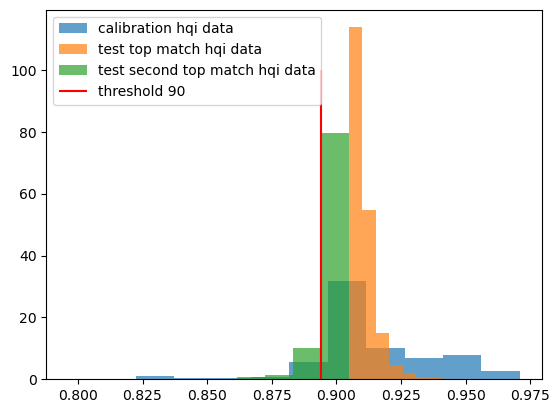

In [65]:
plt.hist(smx_cal[np.arange(label_cal_ir.shape[0]), label_cal_ir], density=True, label='calibration hqi data', alpha=.7)
plt.hist(np.max(smx_test, 1), density=True, label='test top match hqi data', alpha=.7)
plt.hist(np.sort(smx_test, 1)[:,-2], density=True, label='test second top match hqi data', alpha=.7)
#plt.vlines(0.8938658598510795,0, 100, color='red', label='threshold 90%')
#plt.vlines(0.9018570669179764,0, 100, color='red', label='threshold 75%')
plt.vlines(1-qhat,0, 100, color='red', label='threshold '+str(int(100*(1-alpha))))
plt.legend()

In [66]:
X_train_raman.shape, X_test_raman.shape

((188, 1287), (4073, 1287))

In [16]:
# Calculate HQI for calibration set
smx_cal_raman = smx_log(X_train_raman, 
                  X_cal_raman, 
                  label_train_raman, C=0.002)

# Calculate HQI for test set
smx_test_raman = smx_log(X_train_raman, 
                   X_test_raman, 
                   label_train_raman, C=0.002)

#smx_test_all = smx_nn_all(
#        X_train_raman, 
#        X_test_raman, 
#        label_train_raman
#)

#pred_slopp_df = [
#    np.array(label_table_raman.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_raman.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal_raman.shape[0]
#for alpha in [alpha]:
prediction_sets_raman, qhat_raman = conform_pred(smx_cal_raman, smx_test_raman, label_cal_raman, n, alpha, cond=0)

prediction_sets_n_raman = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets_raman]
prediction_sets_size_raman = np.array([len(ps) for ps in prediction_sets_n_raman])

zero_label_raman = np.where(prediction_sets_size_raman == 0)[0]
single_label_raman = np.where(prediction_sets_size_raman == 1)[0]
mult_label_raman = np.where(prediction_sets_size_raman > 1)[0]

print('Sets with zero labels: ' + str(zero_label_raman.shape[0]))
print('Sets with one label: ' + str(single_label_raman.shape[0]))
print('Sets with >1 labels: ' + str(mult_label_raman.shape[0]))
print('Mean set size:', prediction_sets_raman.sum(1).mean())
print('Std set size:', prediction_sets_raman.sum(1).std())
print('HQI cutt off:', 1-qhat_raman)

Sets with zero labels: 0
Sets with one label: 1839
Sets with >1 labels: 2234
Mean set size: 2.5941566412963417
Std set size: 1.735388719105588
HQI cutt off: 0.09032758588127421


In [19]:
smx_test_raman, clf = smx_log(X_train_raman, 
                   X_test_raman, 
                   label_train_raman, C=0.002, return_weights=True)

In [49]:
directory_name

'results/20260124'

In [20]:
prediction_sets = prediction_sets_ir + prediction_sets_raman
prediction_sets_n = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]

In [22]:
pred_sets = pd.DataFrame({'pred_set':prediction_sets_n})
pred_sets['id'] = test_set_ir['id']
pred_sets.to_csv(directory_name+'/CP_results_pasive_paired.csv')

In [51]:
df_log_weights = pd.DataFrame(clf.coef_)
df_log_weights.columns = wl_list_raman
df_log_weights['polymer'] = np.array(label_table_raman.iloc[:, 1])
df_log_weights.to_csv(directory_name+'/log_coefficients_raman.csv')
df_log_weights

,602.0,604.0,606.0,608.0,610.0,612.0,614.0,616.0,618.0,620.0,...,3482.0,3484.0,3486.0,3488.0,3490.0,3492.0,3494.0,3496.0,3498.0,polymer
0,-0.002721,-0.002760,-0.002814,-0.002863,-0.002927,-0.003206,-0.003846,-0.004701,-0.005492,-0.005806,...,-0.000887,-0.000886,-0.000881,-0.000752,-0.000874,-0.000772,-0.000740,-0.000830,-0.000750,Acrylic
1,0.003262,0.004339,0.005316,0.005459,0.005488,0.006689,0.009829,0.013975,0.017862,0.020777,...,0.002109,0.002133,0.002155,0.002134,0.002196,0.002263,0.002314,0.002331,-0.000025,Acrylonitrile Butadiene Styrene
2,-0.000583,-0.000265,-0.000120,-0.000188,-0.000574,-0.001159,-0.001746,-0.002486,-0.002747,-0.002740,...,-0.000671,-0.000662,-0.000654,-0.000645,-0.000648,-0.000660,-0.000662,-0.000652,-0.000522,Cellulose Acetate
3,-0.001748,-0.001867,-0.001807,-0.001658,-0.001619,-0.001785,-0.002185,-0.002709,-0.002853,-0.002605,...,-0.001156,-0.001138,-0.001147,-0.001125,-0.001094,-0.001133,-0.001117,-0.001063,-0.000769,Polyamide
4,-0.001748,-0.002346,-0.002723,-0.002957,-0.003210,-0.003691,-0.004421,-0.005106,-0.005963,-0.006599,...,-0.001497,-0.001236,-0.001258,-0.001367,-0.001311,-0.001485,-0.001250,-0.001121,-0.000565,Polycarbonate
5,-0.004362,-0.004422,-0.004635,-0.005011,-0.005542,-0.006115,-0.006830,-0.007932,-0.009002,-0.009585,...,0.000961,0.001072,0.000938,0.000989,0.001193,0.001051,0.000922,0.000959,0.002276,Polyethylene
6,-0.002395,-0.002710,-0.002972,-0.003102,-0.003215,-0.003552,-0.004488,-0.005984,-0.007666,-0.008321,...,0.000047,-0.000013,0.000126,0.000122,0.000011,-0.000112,-0.000083,0.000027,0.000331,Polyethylene Terephthalate
7,-0.000632,-0.000656,-0.000683,-0.000752,-0.000896,-0.001071,-0.001256,-0.001527,-0.001574,-0.001604,...,0.000505,0.000455,0.000479,0.000321,0.000025,0.000234,0.000587,0.000502,0.000500,Polyethylene Vinyl Acetate
8,0.010776,0.009872,0.008520,0.006948,0.005330,0.003813,0.002490,0.001348,0.000426,-0.000111,...,-0.000348,-0.000352,-0.000353,-0.000344,-0.000348,-0.000339,-0.000324,-0.000306,-0.000093,Polymethyl Methacrylate
9,-0.000475,0.000611,0.001877,0.003246,0.004465,0.005027,0.004720,0.003748,0.002670,0.001644,...,0.001240,0.001119,0.001167,0.001020,0.001145,0.001317,0.001132,0.001256,0.000859,Polypropylene


In [52]:
df_raman_train = pd.DataFrame(X_train_raman)
df_raman_train.columns = wl_list_raman
df_raman_train['polymer'] = np.array(label_table_raman.iloc[label_train_raman, 1])
df_raman_train = df_raman_train.groupby('polymer').mean()
df_raman_train.to_csv(directory_name+'/mean_spectra_raman.csv')

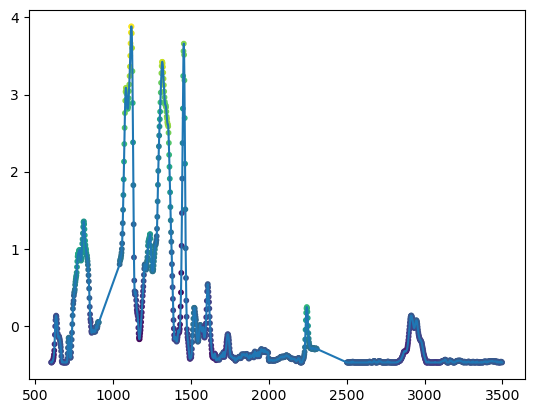

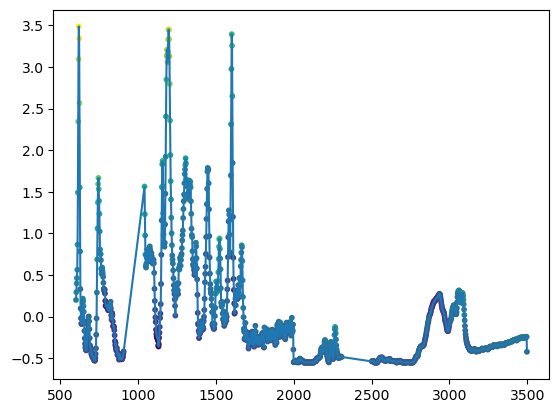

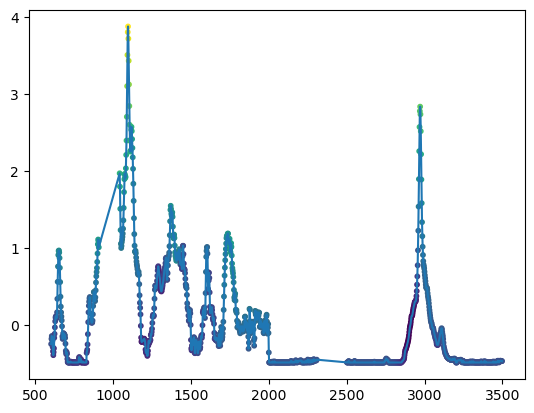

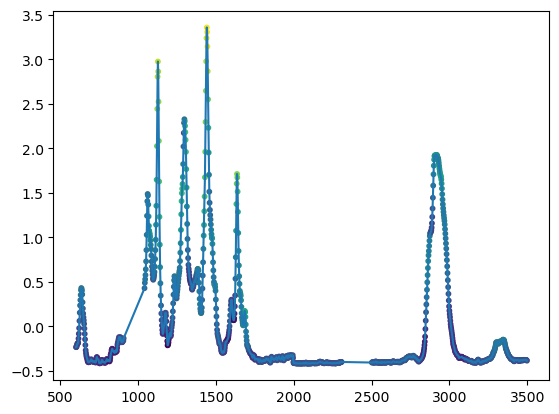

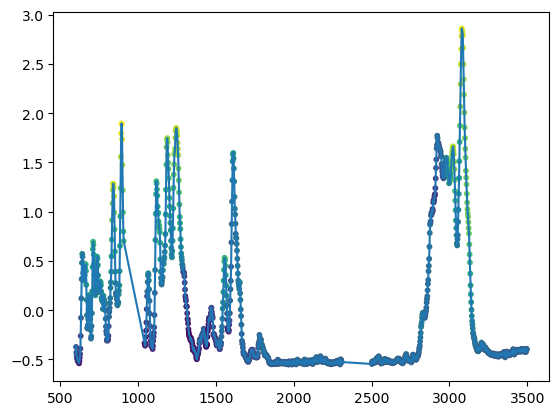

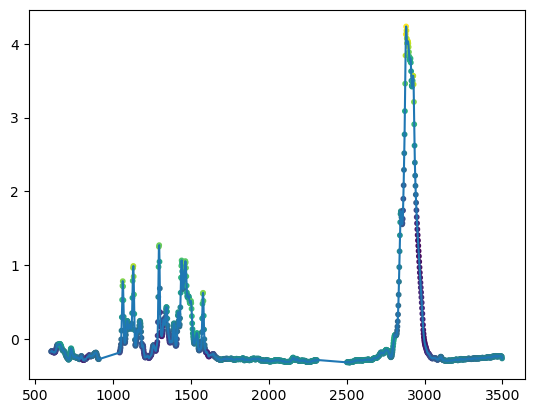

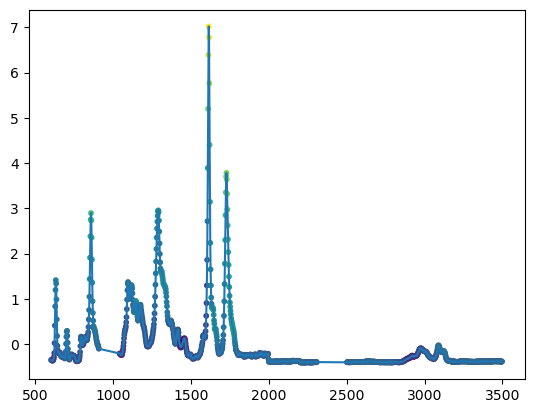

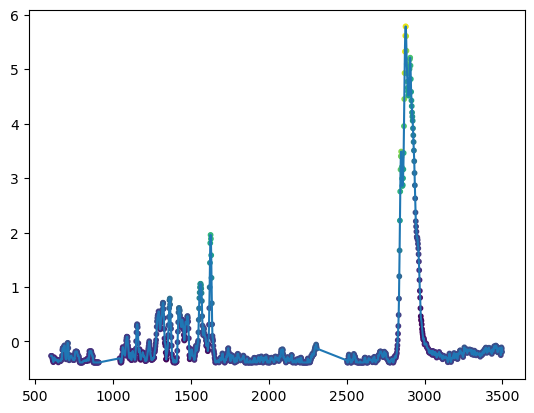

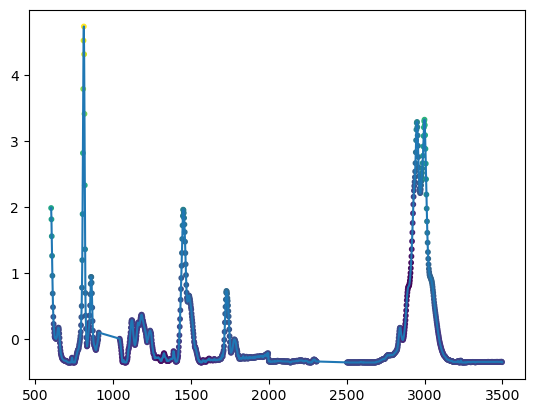

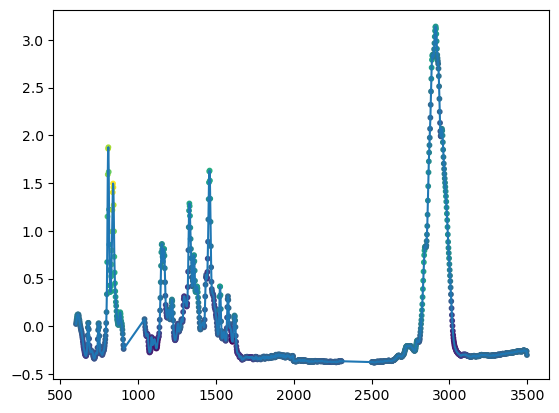

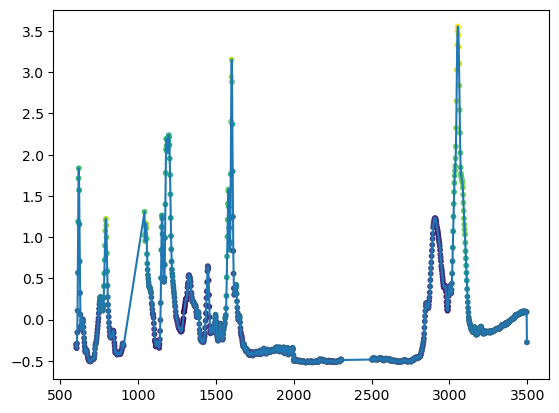

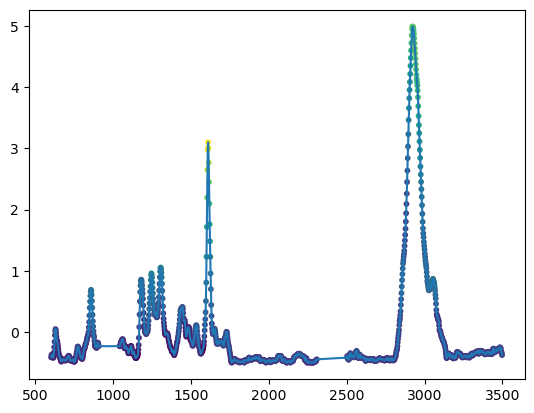

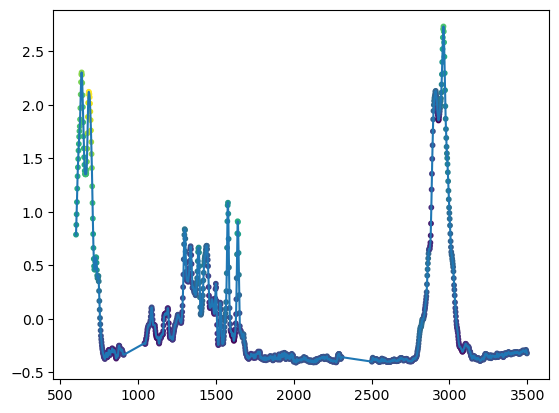

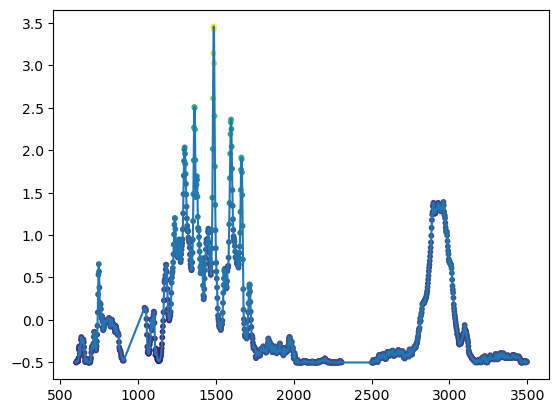

In [47]:
for i in range(14):
    _ = plt.scatter(wl_list_raman,
        df_raman_train.iloc[i,:].T,
                    s=10,
                    c=df_log_weights.iloc[i,:-1]
                 )
    _ = plt.plot(df_raman_train.iloc[i:i+1,:].T,
                 )
    _ = plt.show()

In [20]:
prediction_sets = prediction_sets_ir + prediction_sets_raman
prediction_sets_n = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]

In [21]:

print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Mean set size: 5.822489565430886
Std set size: 3.013785331930531


In [67]:
arg_sort_hqi_ir = np.argsort(1-smx_test_ir, 1)

output_df_ir = pd.DataFrame(
    np.array(
        label_table_ir.iloc[np.argsort(1-smx_test_ir, 1).flatten(), 1]
    ).reshape(smx_test_ir.shape)
)

output_df_ir.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test_ir, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]


for i in range(smx_test_ir.shape[0]):
    #ps_size = prediction_sets.sum(1)[i]
    #output_df_ir.iloc[i, ps_size:14] = ''
    #output_df_ir.iloc[i, 14+ps_size:28] = ''
    
    idx_hqi_ir = np.array([x in prediction_sets_n[i] for j, x in enumerate(list(label_table_ir['polymer']))])[arg_sort_hqi_ir[i,:]]
    output_df_ir.loc[i, ~idx_hqi_ir] = ''
    output_df_hqi.loc[i, ~idx_hqi_ir] = ''
    

output_df_ir = pd.concat([output_df_ir, output_df_hqi], axis=1)

for i in np.unique(label_train_ir):
    poly = label_table_ir.iloc[i, 1]
    idx_label = label_train_ir == i
    idx_top_by_label = np.argmax(smx_test_all_ir[idx_label,:], 0)
    ref_id_list = np.array(reference_library_ir.loc[idx_label,:].iloc[idx_top_by_label,0])
    output_df_ir['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df_ir['id'] = test_set_ir['id']

 #= pd.read_excel('evaluation_data/Passive_MVCP_Review.csv').to_numpy().flatten()

output_df_ir#.query('id in @Passive_RamanOnly_Manual_LikelyMPs').to_csv(directory_name+'/CP_results_passive_unpaired_raman_LikelyMPs.csv')


,top_1,top_2,top_3,top_4,top_5,top_6,top_7,top_8,top_9,top_10,...,id_top_match_flopp_Polyethylene,id_top_match_flopp_Polyethylene Terephthalate,id_top_match_flopp_Polyethylene Vinyl Acetate,id_top_match_flopp_Polymethyl Methacrylate,id_top_match_flopp_Polypropylene,id_top_match_flopp_Polystyrene,id_top_match_flopp_Polyurethane,id_top_match_flopp_Polyvinyl Chloride,id_top_match_flopp_Rubber,id
0,Polystyrene,Polyurethane,Polyvinyl Chloride,,Polypropylene,,,,,,...,,,,,PP 43. Green Fragment.CSV,PS 9. White Foam.CSV,PU 2. Orange Foam.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,,FHS_passive_August2024_B4_20240910_1
1,Polystyrene,Polyvinyl Chloride,Polyurethane,,,Polypropylene,,,,,...,,,,,PP 43. Green Fragment.CSV,PS 9. White Foam.CSV,PU 21. Red Rubber Paving.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,,FHS_passive_August2024_B4_20240910_2
2,Polystyrene,Polyurethane,,,Polypropylene,,,,,,...,,,,,PP 43. Green Fragment.CSV,PS 9. White Foam.CSV,PU 21. Red Rubber Paving.CSV,,,FHS_passive_August2024_B4_20240910_3
3,Polystyrene,Polyurethane,Polyvinyl Chloride,,Polypropylene,,,,,,...,,,,,PP 43. Green Fragment.CSV,PS 9. White Foam.CSV,PU 21. Red Rubber Paving.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,,FHS_passive_August2024_B4_20240910_4
4,Polystyrene,Polyurethane,Polyvinyl Chloride,,,Polypropylene,,,,,...,,,,,PP 3. Yellow Fragment.CSV,PS 9. White Foam.CSV,PU 21. Red Rubber Paving.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,,FHS_passive_August2024_B4_20240910_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4068,Polyurethane,Polystyrene,Polyvinyl Chloride,,,,Polypropylene,,,,...,,,,,PP 3. Yellow Fragment.CSV,PS 9. White Foam.CSV,PU 21. Red Rubber Paving.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,,IAO_passive_June2024_G7_20240801_39
4069,Polystyrene,Polyvinyl Chloride,Polypropylene,Polyethylene Terephthalate,,,,,,,...,,PET 15. Black Cable Cover Fragment.CSV,,,PP 9. White Fork Fragment.CSV,PS 8. White Foam.CSV,,PVC 23. Pink Yoga Mat Foam.CSV,,IAO_passive_June2024_G7_20240801_40
4070,Polyurethane,Polystyrene,Polyvinyl Chloride,,,Polypropylene,,,,,...,,,,,PP 43. Green Fragment.CSV,PS 9. White Foam.CSV,PU 21. Red Rubber Paving.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,,IAO_passive_June2024_G7_20240801_41
4071,Polystyrene,Polyurethane,,,,Polypropylene,,,,,...,,,,,PP 43. Green Fragment.CSV,PS 9. White Foam.CSV,PU 21. Red Rubber Paving.CSV,,,IAO_passive_June2024_G7_20240801_42


In [92]:
output_df_ir.iloc[0,:]

top_1                                                                          Polystyrene
top_2                                                                         Polyurethane
top_3                                                                   Polyvinyl Chloride
top_4                                                                                     
top_5                                                                        Polypropylene
top_6                                                                                     
top_7                                                                                     
top_8                                                                                     
top_9                                                                                     
top_10                                                                                    
top_11                                                                                    

In [93]:
output_df_raman.iloc[0,:]

top_1                                Polypropylene
top_2                                             
top_3                                             
top_4                           Polyvinyl Chloride
top_5                                             
top_6                                  Polystyrene
top_7                                             
top_8                                             
top_9                                             
top_10                                Polyurethane
top_11                                            
top_12                                            
top_13                                            
top_14                                            
top_1_hqi                                 0.635926
top_2_hqi                                         
top_3_hqi                                         
top_4_hqi                                 0.050024
top_5_hqi                                         
top_6_hqi                      

In [72]:
arg_sort_hqi_raman = np.argsort(1-smx_test_raman, 1)

output_df_raman = pd.DataFrame(
    np.array(
        label_table_raman.iloc[np.argsort(1-smx_test_raman, 1).flatten(), 1]
    ).reshape(smx_test_raman.shape)
)

output_df_raman.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test_raman, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]

for i in range(smx_test_raman.shape[0]):
    #ps_size = prediction_sets.sum(1)[i]
    #output_df_raman.iloc[i, ps_size:14] = ''
    #output_df_raman.iloc[i, 14+ps_size:28] = ''
    
    idx_hqi_raman = np.array([x in prediction_sets_n[i] for j, x in enumerate(list(label_table_raman['polymer']))])[arg_sort_hqi_raman[i,:]]
    output_df_raman.loc[i, ~idx_hqi_raman] = ''
    output_df_hqi.loc[i, ~idx_hqi_raman] = ''
    
output_df_raman = pd.concat([output_df_raman, output_df_hqi], axis=1)

#for i in np.unique(label_train_raman):
#    poly = label_table_raman.iloc[i, 1]
#    idx_label = label_train_raman == i
#    idx_top_by_label = np.argmax(smx_test_all[idx_label,:], 0)
#    ref_id_list = np.array(reference_library_raman.loc[idx_label,:].iloc[idx_top_by_label,0])
#    output_df_raman['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df_raman['id'] = test_set_ir['id']

 #= pd.read_excel('evaluation_data/Passive_MVCP_Review.csv').to_numpy().flatten()

output_df_raman#.query('id in @Passive_RamanOnly_Manual_LikelyMPs').to_csv(directory_name+'/CP_results_passive_unpaired_raman_LikelyMPs.csv')


,top_1,top_2,top_3,top_4,top_5,top_6,top_7,top_8,top_9,top_10,...,top_6_hqi,top_7_hqi,top_8_hqi,top_9_hqi,top_10_hqi,top_11_hqi,top_12_hqi,top_13_hqi,top_14_hqi,id
0,Polypropylene,,,Polyvinyl Chloride,,Polystyrene,,,,Polyurethane,...,0.039375,,,,0.014244,,,,,FHS_passive_August2024_B4_20240910_1
1,Polypropylene,,Polyvinyl Chloride,,,Polystyrene,,,Polyurethane,,...,0.032939,,,0.012282,,,,,,FHS_passive_August2024_B4_20240910_2
2,Polypropylene,,,,,Polystyrene,,,Polyurethane,,...,0.032842,,,0.011052,,,,,,FHS_passive_August2024_B4_20240910_3
3,Polypropylene,,,Polyvinyl Chloride,,Polystyrene,,,Polyurethane,,...,0.03503,,,0.012448,,,,,,FHS_passive_August2024_B4_20240910_4
4,Polypropylene,,,Polyvinyl Chloride,,Polystyrene,,,Polyurethane,,...,0.047912,,,0.022035,,,,,,FHS_passive_August2024_B4_20240910_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4068,Polypropylene,,,Polyvinyl Chloride,,Polystyrene,,Polyurethane,,,...,0.03928,,0.014477,,,,,,,IAO_passive_June2024_G7_20240801_39
4069,Polypropylene,Polystyrene,,Polyvinyl Chloride,,Polyethylene Terephthalate,,,,,...,0.04305,,,,,,,,,IAO_passive_June2024_G7_20240801_40
4070,Polypropylene,,,Polystyrene,,Polyvinyl Chloride,,,Polyurethane,,...,0.039457,,,0.012125,,,,,,IAO_passive_June2024_G7_20240801_41
4071,Polypropylene,,,,,Polystyrene,,,Polyurethane,,...,0.034607,,,0.011533,,,,,,IAO_passive_June2024_G7_20240801_42


In [81]:
Passive_MVCP_Review = pd.read_csv('evaluation_data/Passive_MVCP_Review.csv')['ID'].to_numpy().flatten()
output_df_raman.query('id in @Passive_MVCP_Review').to_csv(directory_name+'/CP_results_passive_paired_raman_LikelyMPs.csv')
output_df_ir.query('id in @Passive_MVCP_Review').to_csv(directory_name+'/CP_results_passive_paired_ir_LikelyMPs.csv')


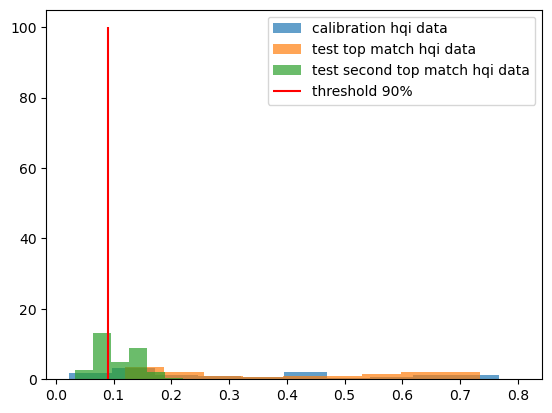

In [83]:
plt.hist(smx_cal[np.arange(label_cal_ir.shape[0]), label_cal_ir], density=True, label='calibration hqi data', alpha=.7)
plt.hist(np.max(smx_test, 1), density=True, label='test top match hqi data', alpha=.7)
plt.hist(np.sort(smx_test, 1)[:,-2], density=True, label='test second top match hqi data', alpha=.7)
plt.vlines(1-qhat,0, 100, color='red', label='threshold 90%')
plt.legend()

In [84]:
np.mean(np.argmax(smx_cal,1) == label_cal_raman)#[np.arange(label_cal_raman.shape[0]),label_cal_raman]

0.6390243902439025

In [389]:
smx_all_IR = 1-np.power(smx_nn(X_train_ir, X_cal_ir, label_train_ir),1)
smx_all_Raman = 1-np.power(smx_log(X_train_raman, X_cal_raman, label_train_raman, C=0.002),1)

smx_all_IR_test = 1-np.power(smx_nn(X_train_ir, X_test_ir, label_train_ir),1)
smx_all_Raman_test = 1-np.power(smx_log(X_train_raman, X_test_raman, label_train_raman, C=0.002),1)


score_list = [smx_all_IR, smx_all_Raman]
score_list_test = [smx_all_IR_test, smx_all_Raman_test]

#alpha = .1
seed = 1
K = 2
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
U_list = gen_u(K, seed=0)

for i in range(K):
    #quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
    quant_smx, cal_smx, quant_labels, cal_labels, idx_quant = split_cal_test(score_list[i], label_cal_ir, cal_prop=0.1, seed=seed)
    
    val_smx, val_labels = score_list_test[i], None
    
    #y_val = list(label_table.iloc[val_labels,1])
    
    #y_val_ir = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_ir'])
    #y_val_raman = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_raman'])
    
    quant_smx_list.append(quant_smx)
    #rest_smx_list.append(rest_smx)
    cal_smx_list.append(cal_smx)
    val_smx_list.append(val_smx)

n = cal_labels.shape[0]

prediction_sets = mvcp_2(quant_smx_list, 
                                             quant_labels,   
                                             cal_smx_list,   
                                             cal_labels,   
                                             val_smx_list,   
                                             alpha,     
                                             val_labels,                 
                                             U=U_list[0])

prediction_sets_n_mvcp = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_mvcp])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 1118
Sets with one label: 1389
Sets with >1 labels: 1566
Mean set size: 1.6037318929535969
Std set size: 1.6783030194511135


In [113]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_ir':prediction_sets_n,
                          'prection_set_raman':prediction_sets_n_raman,
                          'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])


output_df.to_csv(directory_name+'/CP_results_passive_paired.csv')

In [14]:
#output_df_p = pd.read_csv('CP_restuls.csv')
#del output_df_p['Unnamed: 0']
#output_df_p

#output_df_compare = pd.merge(output_df.iloc[:,[0,4,5,6,7,8,9]], output_df_p.iloc[:,[0,4,5,6,7,8,9]],on='id')
#output_df_compare

#(np.mean([len(x) for x in output_df['prection_set_ir']]), 
#np.mean([len(x) for x in output_df['prection_set_raman']]),
#np.mean([len(x) for x in output_df['prection_set_mvcp']]))

#(np.mean([x.count(',')+1 for x in output_df_p['prection_set_ir']]), 
#np.mean([x.count(',')+1 for x in output_df_p['prection_set_raman']]),
#np.mean([x.count(',')+1 for x in output_df_p['prection_set_mvcp']]))

# Unpaired Raman

In [83]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df, 
                              passive_data_raman_unpaired_ram)

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                 calibration_set_raman,
                                 test_set_raman)


(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                              passive_data_ir_unpaired_ram)

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)



        
#pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
#                              slopp_df['polymer'], 
#                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

#pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
#                              flopp_df['polymer'], 
#                              np.array(test_set_ir.iloc[:,3:]), r_min=0)


In [84]:
# Calculate HQI for calibration set
smx_cal = smx_log(X_train_raman, 
                 X_cal_raman, 
                 label_train_raman, C=0.002)

# Calculate HQI for test set
smx_test = smx_log(X_train_raman, 
                  X_test_raman, 
                  label_train_raman, C=0.002)

#smx_test_all = smx_nn_all(
#        X_train_raman, 
#        X_test_raman, 
#        label_train_raman
#)

#pred_slopp_df = [
#    np.array(label_table_raman.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_raman.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_raman, n, alpha, cond=0)

prediction_sets_n_raman = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_raman])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 958
Sets with >1 labels: 866
Mean set size: 2.3678728070175437
Std set size: 1.6926954373043805


In [86]:
output_df = pd.DataFrame(
    np.array(
        label_table_raman.iloc[np.argsort(1-smx_test, 1).flatten(), 1]
    ).reshape(smx_test.shape)
)

output_df.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]

output_df = pd.concat([output_df, output_df_hqi], axis=1)

for i in range(smx_test.shape[0]):
    ps_size = prediction_sets.sum(1)[i]
    output_df.iloc[i, ps_size:14] = ''
    output_df.iloc[i, 14+ps_size:28] = ''

#for i in np.unique(label_train_raman):
#    poly = label_table_raman.iloc[i, 1]
#    idx_label = label_train_raman == i
#    idx_top_by_label = np.argmax(smx_test_all[idx_label,:], 0)
#    ref_id_list = np.array(reference_library_raman.loc[idx_label,:].iloc[idx_top_by_label,0])
#    output_df['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df['id'] = test_set_ir['id']

Passive_RamanOnly_Manual_LikelyMPs = pd.read_excel('evaluation_data/Passive_RamanOnly_Manual_LikelyMPs.xlsx', header=None).to_numpy().flatten()

output_df.query('id in @Passive_RamanOnly_Manual_LikelyMPs').to_csv(directory_name+'/CP_results_passive_unpaired_raman_LikelyMPs.csv')


In [118]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          #'prection_set_ir':prediction_sets_n,
                          'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

#output_df['polymer_flopp'] = np.array(pred_flopp_df[0])#['polymer_ref']
#output_df['hqi_flopp'] = pred_flopp_df[1]#['hqi_ref']
#output_df['id_top_match_flopp'] = np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])


output_df.to_csv(directory_name+'/CP_results_passive_unpaired_raman.csv')

# Unpaired IR

In [23]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df, 
                              passive_data_raman_unpaired_ir)

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                 calibration_set_raman,
                                 test_set_raman)


(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                              passive_data_ir_unpaired_ir)

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)



        
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(test_set_ir.iloc[:,3:]), r_min=0)


In [24]:
# Calculate HQI for calibration set
smx_cal = smx_nn(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test = smx_nn(X_train_ir, X_test_ir, label_train_ir)

smx_test_all = smx_nn_all(
        X_train_ir, 
        X_test_ir, 
        label_train_ir
)

pred_flopp_df = [
    np.array(label_table_ir.iloc[np.argmax(smx_test, 1),1]),
    np.max(smx_test, 1),
    np.array(reference_library_ir.iloc[np.argmax(smx_test_all, 0),0])
]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_ir, n, alpha, cond=0)

prediction_sets_n = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 765
Sets with >1 labels: 1331
Mean set size: 2.5229007633587788
Std set size: 2.078940749277634


In [26]:
pred_sets = pd.DataFrame({'pred_set':prediction_sets_n})
pred_sets['id'] = test_set_ir['id']
pred_sets.to_csv(directory_name+'/CP_results_pasive_onlyIR.csv')

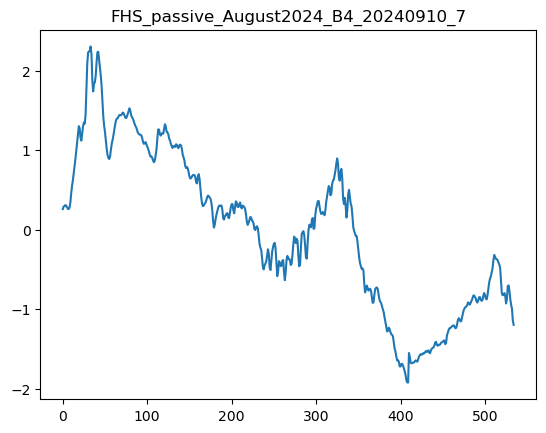

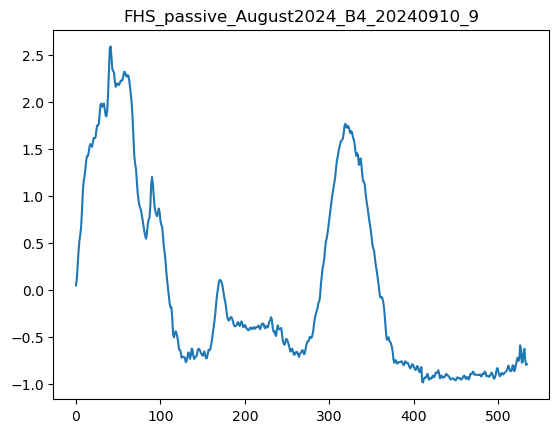

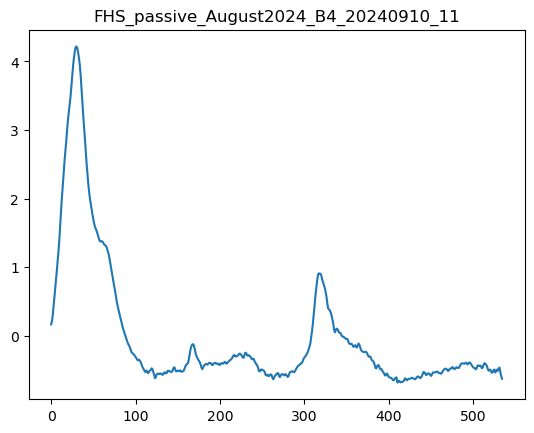

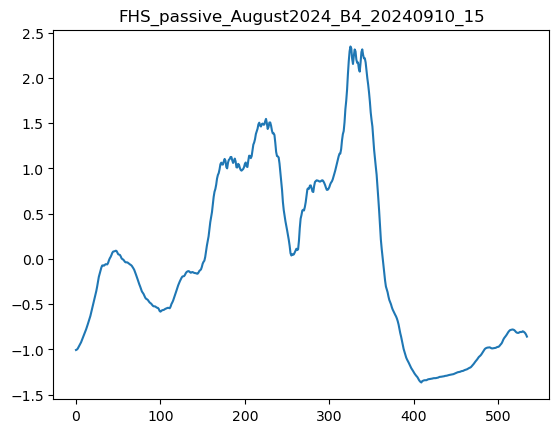

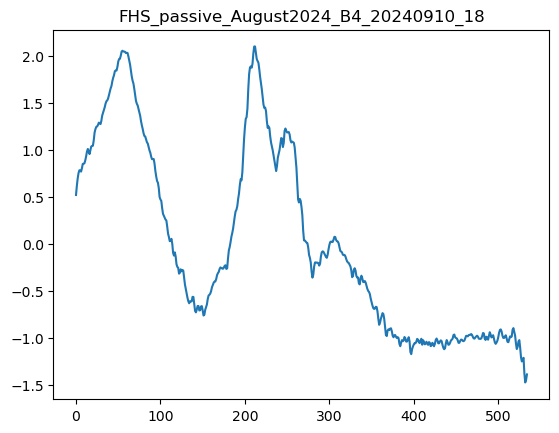

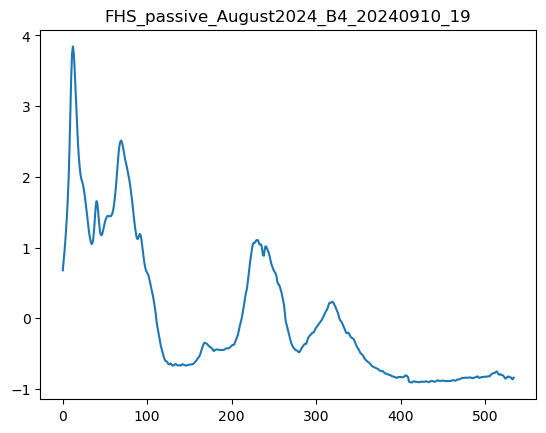

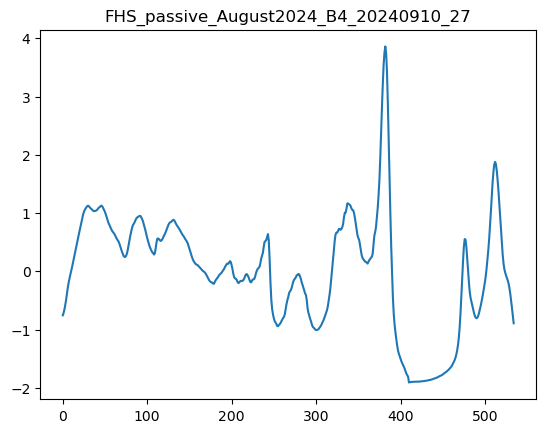

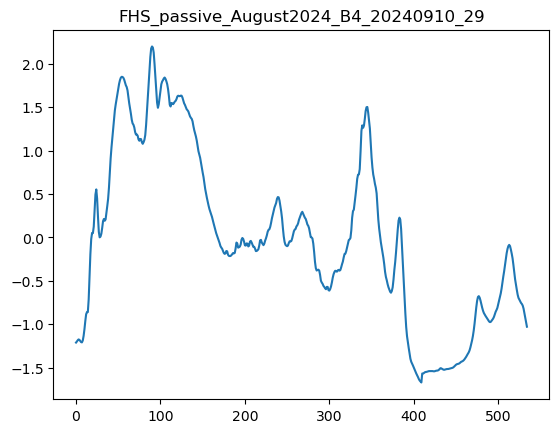

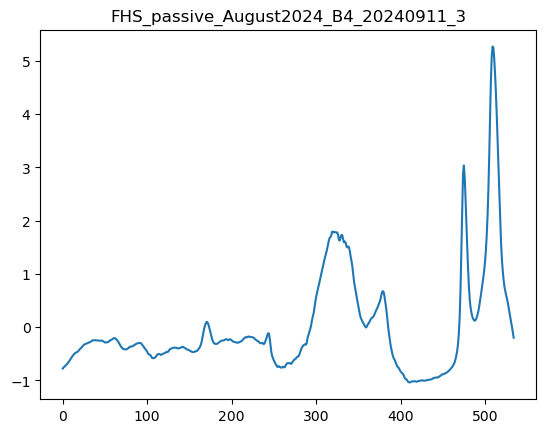

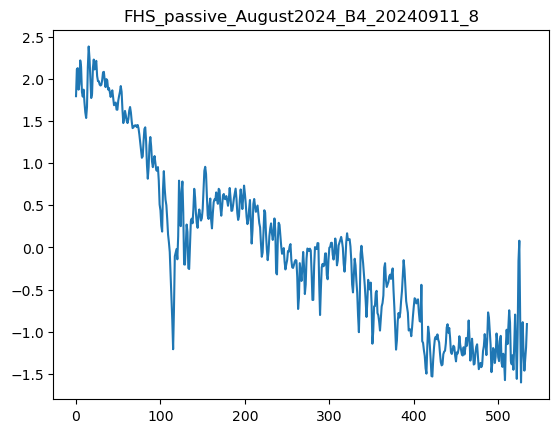

In [369]:
for i, id_ in enumerate(test_set_ir['id'][:10]):
    _ = plt.plot(X_test_ir[i].T)
    _ = plt.title(id_)
    _ = plt.show()

In [362]:
np.mean(smx_cal.argmax(1) == label_cal_ir)

0.6292682926829268

In [364]:
np.mean(smx_cal.argmax(1) == label_cal_ir)

0.6048780487804878

In [90]:
output_df = pd.DataFrame(np.array(label_table_ir.iloc[np.argsort(1-smx_test, 1).flatten(), 1]).reshape(smx_test.shape))
output_df.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]

output_df = pd.concat([output_df, output_df_hqi], axis=1)

for i in range(smx_test.shape[0]):
    ps_size = prediction_sets.sum(1)[i]
    output_df.iloc[i, ps_size:14] = ''
    output_df.iloc[i, 14+ps_size:28] = ''

for i in np.unique(label_train_ir):
    poly = label_table_ir.iloc[i, 1]
    idx_label = label_train_ir == i
    idx_top_by_label = np.argmax(smx_test_all[idx_label,:], 0)
    ref_id_list = np.array(reference_library_ir.loc[idx_label,:].iloc[idx_top_by_label,0])
    output_df['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df['id'] = test_set_ir['id']

FINAL_PTIR_LikelyMPs = pd.read_excel('evaluation_data/FINAL_PTIR_LikelyMPs.xlsx', header=None).to_numpy().flatten()

output_df.query('id in @FINAL_PTIR_LikelyMPs').to_csv(directory_name+'/CP_results_passive_unpaired_ir_LikelyMPs.csv')


In [122]:
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_ir':prediction_sets_n,
                          #'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

#output_df['polymer_slopp'] = np.array(pred_slopp_df[0])#['polymer_ref']
#output_df['hqi_slopp'] = pred_slopp_df[1]#['hqi_ref']
#output_df['id_top_match_slopp'] = np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])


output_df.to_csv(directory_name+'/CP_results_passive_unpaired_ir.csv')

In [127]:
label_table_summary = label_table_raman.copy()
label_table_summary['res'] = 0
for i in range(label_table_raman.shape[0]):
    p = label_table_raman.iloc[i, 1]
    label_table_summary.iloc[i,2] = np.sum([p in x for x in prediction_sets_n_mvcp if len(x)==1])

label_table_summary.query('res>0')

,label,polymer,res
0,0,Acrylic,1
1,1,Acrylonitrile Butadiene Styrene,3
3,3,Polyamide,24
4,4,Polycarbonate,3
5,5,Polyethylene,6
8,8,Polymethyl Methacrylate,3
9,9,Polypropylene,85
10,10,Polystyrene,1476
11,11,Polyurethane,4
12,12,Polyvinyl Chloride,3
